## Candidate Model Selection

I selected a support vector machine as a candidate model for forecasting weekly Karenia brevis conditions in Sarasota. This notebook evaluates forecasts at one-, two-, and four-week horizons using the merged weekly dataset.

I evaluated 3 SVM configurations.

I use forward-chaining evaluation organized by August–July bloom years. For each fold, the model is trained only on observations whose target dates precede the start of the test period. SVMs cannot handle missing values and are sensitive to feature scale. To account for this, each model is wrapped in a pipeline that applies standardization fitted on the training fold only. Performance is evaluated using accuracy, macro-F1, macro-precision, macro-recall, and one-vs-rest macro ROC-AUC.

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt
import os
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

warnings.filterwarnings("ignore")

## Connect To Drive

In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data'

if os.path.exists(DATA_DIR):
    print(f"Data directory '{DATA_DIR}' exists.")
    os.chdir(DATA_DIR)
else:
    print(f"Data directory '{DATA_DIR}' does not exist.")

print(os.getcwd())
print(os.listdir())

Mounted at /content/drive
Data directory '/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data' exists.
/content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data
['bradentonFL_tempData.csv', 'florida_cyanotoxins_2015-01-01_to_2026-06-17.csv', 'habsos_cellcounts.csv', 'cleaned', 'NutrientsFL_2006_2025.csv', 'MoteMarine_BottomTemp.csv', 'engineered', 'merged', 'ChlorophyllaConcentrationSarasota.txt', 'ChlorophyllaConcentrationSarasota_Dataset2.txt', 'SarasotaWindData.txt', 'Sarasota_Wind&Temp.csv', 'ChlorophyllaConcentrationSarasota_engineered.csv', 'chirps20GlobalDailyP05_0878_d358_0bc6.txt', 'chirps20GlobalDailyP05_0878_d358_0bc6_cleaned.csv', 'wind_daily.csv', 'svm_fold_results.csv', 'svm_summary.csv', 'results']


## Load the Weekly Dataset

Load merged_weekly_sarasota.csv and inspect its columns. The dataset includes K. brevis measurements, environmental variables, lagged and rolling features, and targets for one-, two-, and four-week forecasts.

In [3]:
# Load the existing dataset
dataset = pd.read_csv("merged/merged_weekly_sarasota.csv")
print(dataset.shape)

# Check class balance for each forecast target
for target in ["target_1w", "target_2w", "target_4w"]:
    print(target, dataset[target].value_counts(dropna=False).to_dict())

# Check the most incomplete columns (for SVMs specifically)
dataset.isna().mean().sort_values(ascending=False).head(10)

(853, 89)
target_1w {0.0: 535, 2.0: 144, nan: 114, 1.0: 60}
target_2w {0.0: 534, 2.0: 144, nan: 115, 1.0: 60}
target_4w {0.0: 532, 2.0: 144, nan: 117, 1.0: 60}


,0
bay_tss_8w,1.000000
creek_chl_uncorr_8w,0.815944
mote_water_temp_c,0.776084
wind_u_4w,0.767878
wind_v_4w,0.767878
wind_u,0.766706
wind_v,0.766706
pressure_mb,0.766706
wind_speed,0.766706
ksrq_air_temp_c,0.766706


## Prepare the Evaluation

Convert week_ending to a datetime value and sort observations chronologically. Exclude the date column and all 3 target columns from the model inputs. Define the SVM configurations and a scoring helper.

In [4]:
# Convert dates and sort chronologically
dataset["week_ending"] = pd.to_datetime(dataset["week_ending"])
dataset = dataset.sort_values("week_ending").reset_index(drop=True)

# Columns that should not be used as model features
exclude = ["week_ending", "target_1w", "target_2w", "target_4w"]


def svm_model(kernel="rbf", class_weight=None):
    # Impute and scale inside the pipeline so both are fit on training data only
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel=kernel,
            C=1.0,
            gamma="scale",
            class_weight=class_weight,
            probability=True,
            random_state=42
        ))
    ])


# SVM configurations to evaluate
models = {
    "SVM RBF (default)":      lambda: svm_model("rbf"),
    "SVM RBF (balanced)":     lambda: svm_model("rbf", "balanced"),
    "SVM Linear (balanced)":  lambda: svm_model("linear", "balanced"),
}


def score_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    metrics = {
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "macro_precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, predictions, average="macro", zero_division=0),
    }

    # One-vs-rest ROC-AUC over classes that can be scored in this test year
    probabilities = model.predict_proba(X_test)
    classes = list(model.classes_)
    aucs = [
        roc_auc_score((y_test == c).astype(int), probabilities[:, classes.index(c)])
        for c in classes
        if (y_test == c).any() and (y_test != c).any()
    ]
    metrics["roc_auc_ovr"] = np.mean(aucs) if aucs else np.nan

    return metrics


# Store metrics for every configuration, horizon, and test year
results = []

## Evaluate the SVM Models

Evaluate one-, two-, and four-week forecasts using forward-chaining folds labeled 2016–2026. Each test period runs from August 1 of the preceding year to August 1 of the labeled year, with the ending date excluded. Test observations are assigned by their forecast-origin dates.

For each horizon, remove observations with missing target values and calculate the corresponding target dates. Training observations are included only when their target dates fall before the test period begins, which keeps training labels from extending into the test period. Folds with no training data, no test data, or fewer than two training classes are skipped.

Within each eligible fold, every SVM configuration is trained on all eligible features and evaluated on the same test observations.

In [5]:
# Evaluate 1-, 2-, and 4-week prediction horizons
for horizon in [1, 2, 4]:

    target = f"target_{horizon}w"

    # Remove rows without a known target
    data = dataset.dropna(subset=[target]).copy()

    # Record when the forecast target occurs
    data["target_week"] = (
        data["week_ending"] + pd.to_timedelta(7 * horizon, unit="D")
    )

    # All eligible input features
    feature_cols = [col for col in dataset.columns if col not in exclude]

    X = data[feature_cols]
    y = data[target].astype(int)

    # Forward-chaining evaluation by August-July bloom year
    for year in range(2016, 2027):

        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        test_end = pd.Timestamp(year=year, month=8, day=1)

        test_mask = (
            (data["week_ending"] >= test_start) &
            (data["week_ending"] < test_end)
        )

        # Train only on examples whose target date is before the test year
        train_mask = data["target_week"] < test_start

        X_train, y_train = X.loc[train_mask], y.loc[train_mask]
        X_test, y_test = X.loc[test_mask], y.loc[test_mask]

        # Skip folds without enough data or with only one training class
        if len(X_train) == 0 or len(X_test) == 0:
            continue

        if y_train.nunique() < 2:
            continue

        line = f"{horizon}-week | {year} | n_test={len(X_test):3d}"

        for model_name, make_model in models.items():

            model = make_model()
            model.fit(X_train, y_train)

            metrics = score_model(model, X_test, y_test)

            results.append({
                "horizon": horizon,
                "test_year": year,
                "model": model_name,
                "n_test": len(X_test),
                **metrics
            })

            line += f" | {model_name}: {metrics['accuracy']:.3f}"

        print(line)

1-week | 2016 | n_test= 53 | SVM RBF (default): 0.453 | SVM RBF (balanced): 0.453 | SVM Linear (balanced): 0.717
1-week | 2017 | n_test= 52 | SVM RBF (default): 0.577 | SVM RBF (balanced): 0.596 | SVM Linear (balanced): 0.712
1-week | 2018 | n_test= 52 | SVM RBF (default): 0.731 | SVM RBF (balanced): 0.577 | SVM Linear (balanced): 0.558
1-week | 2019 | n_test= 52 | SVM RBF (default): 0.654 | SVM RBF (balanced): 0.654 | SVM Linear (balanced): 0.769
1-week | 2020 | n_test= 52 | SVM RBF (default): 0.885 | SVM RBF (balanced): 0.827 | SVM Linear (balanced): 0.750
1-week | 2021 | n_test= 48 | SVM RBF (default): 0.646 | SVM RBF (balanced): 0.604 | SVM Linear (balanced): 0.333
1-week | 2022 | n_test=  4 | SVM RBF (default): 0.750 | SVM RBF (balanced): 0.500 | SVM Linear (balanced): 0.500
1-week | 2023 | n_test= 11 | SVM RBF (default): 0.455 | SVM RBF (balanced): 0.273 | SVM Linear (balanced): 0.091
1-week | 2024 | n_test= 33 | SVM RBF (default): 1.000 | SVM RBF (balanced): 0.030 | SVM Linear (

## Summarize and Visualize Evaluation Results

Display accuracy, macro-F1, macro-precision, macro-recall, and ROC-AUC for each model, forecast horizon, and test year. Then calculate the arithmetic mean of each metric across the available test years for each model. These summaries give each included test year equal weight rather than pooling predictions across years. Several test years contain very few weeks (for example, 2022 and 2023), so the annual plots should be read alongside the averages.

Plot annual accuracy, macro-F1, and ROC-AUC to show how each configuration's performance varies across test periods.

In [6]:
# Convert saved results into a DataFrame
results_df = pd.DataFrame(results)

metric_cols = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "roc_auc_ovr"]

# Display metrics for each horizon, year, and model
display(
    results_df.sort_values(
        ["horizon", "test_year", "model"]
    ).reset_index(drop=True)
)

# Summarize average performance across test years
summary_df = (
    results_df
    .groupby(["horizon", "model"])[metric_cols]
    .mean()
    .round(4)
    .reset_index()
)

print("Average performance across available test years:")
display(summary_df)

# Save results so they can be reused outside the notebook
results_df.to_csv("svm_fold_results.csv", index=False)
summary_df.to_csv("svm_summary.csv", index=False)

,horizon,test_year,model,n_test,accuracy,macro_f1,macro_precision,macro_recall,roc_auc_ovr
0,1,2016,SVM Linear (balanced),53,0.716981,0.594106,0.605436,0.626661,0.781660
1,1,2016,SVM RBF (balanced),53,0.452830,0.264405,0.477124,0.368421,0.720161
2,1,2016,SVM RBF (default),53,0.452830,0.264405,0.477124,0.368421,0.691382
3,1,2017,SVM Linear (balanced),52,0.711538,0.590768,0.604762,0.596561,0.759852
4,1,2017,SVM RBF (balanced),52,0.596154,0.493939,0.523462,0.511905,0.791563
...,...,...,...,...,...,...,...,...,...
94,4,2025,SVM RBF (balanced),52,0.653846,0.406189,0.428030,0.433333,0.802911
95,4,2025,SVM RBF (default),52,0.576923,0.243902,0.192308,0.333333,0.836573
96,4,2026,SVM Linear (balanced),36,0.583333,0.368421,0.500000,0.291667,NaN
97,4,2026,SVM RBF (balanced),36,0.527778,0.345455,0.500000,0.263889,NaN


Average performance across available test years:


,horizon,model,accuracy,macro_f1,macro_precision,macro_recall,roc_auc_ovr
0,1,SVM Linear (balanced),0.6060,0.4339,0.4574,0.4384,0.5580
1,1,SVM RBF (balanced),0.5694,0.4295,0.5362,0.4479,0.7620
2,1,SVM RBF (default),0.7094,0.5430,0.5898,0.5941,0.7560
3,2,SVM Linear (balanced),0.5099,0.3553,0.4061,0.3725,0.6020
4,2,SVM RBF (balanced),0.5790,0.4023,0.4750,0.4196,0.7240
5,2,SVM RBF (default),0.6850,0.4579,0.4949,0.5162,0.7326
6,4,SVM Linear (balanced),0.4887,0.3869,0.4562,0.4039,0.6607
7,4,SVM RBF (balanced),0.5009,0.3692,0.4711,0.3732,0.7285
8,4,SVM RBF (default),0.6507,0.4513,0.4777,0.5176,0.7212


## Accuracy by Test Year

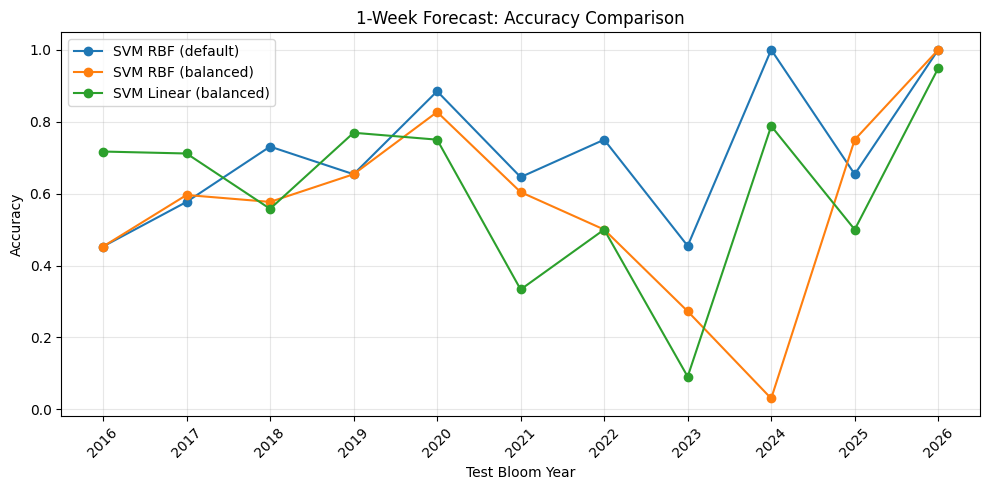

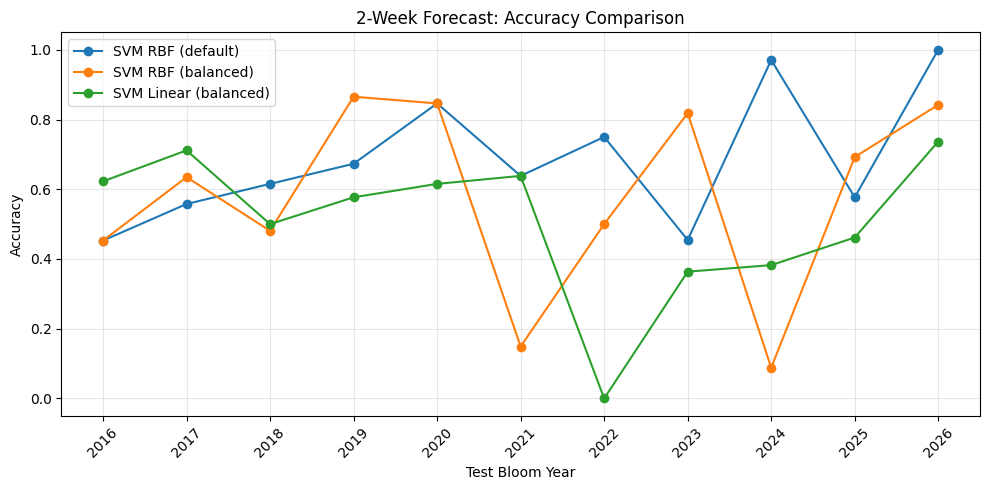

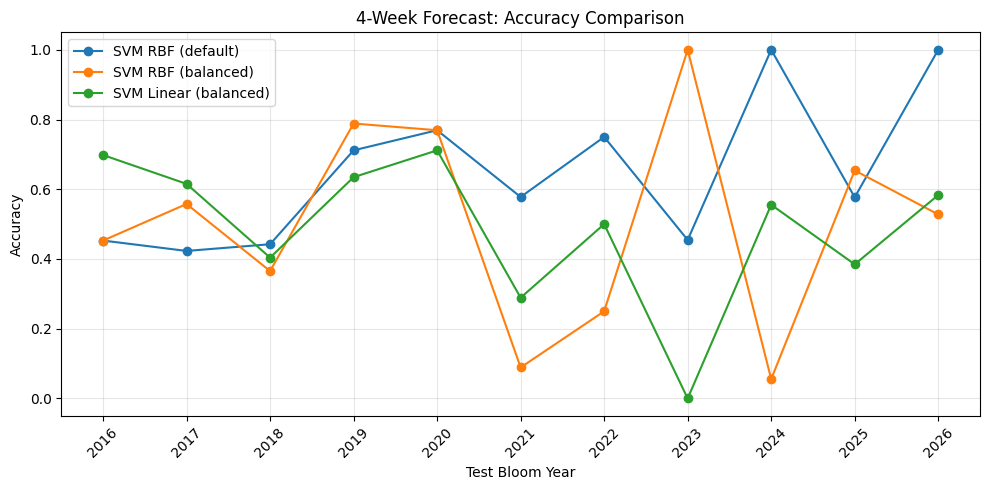

In [7]:
# Plot test-year accuracy for each prediction horizon
for horizon in [1, 2, 4]:

    horizon_results = results_df[results_df["horizon"] == horizon]

    plt.figure(figsize=(10, 5))

    for model_name in horizon_results["model"].unique():

        model_results = horizon_results[
            horizon_results["model"] == model_name
        ].sort_values("test_year")

        plt.plot(
            model_results["test_year"],
            model_results["accuracy"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Test Bloom Year")
    plt.ylabel("Accuracy")
    plt.title(f"{horizon}-Week Forecast: Accuracy Comparison")
    plt.xticks(range(2016, 2027), rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Macro-F1 by Test Year

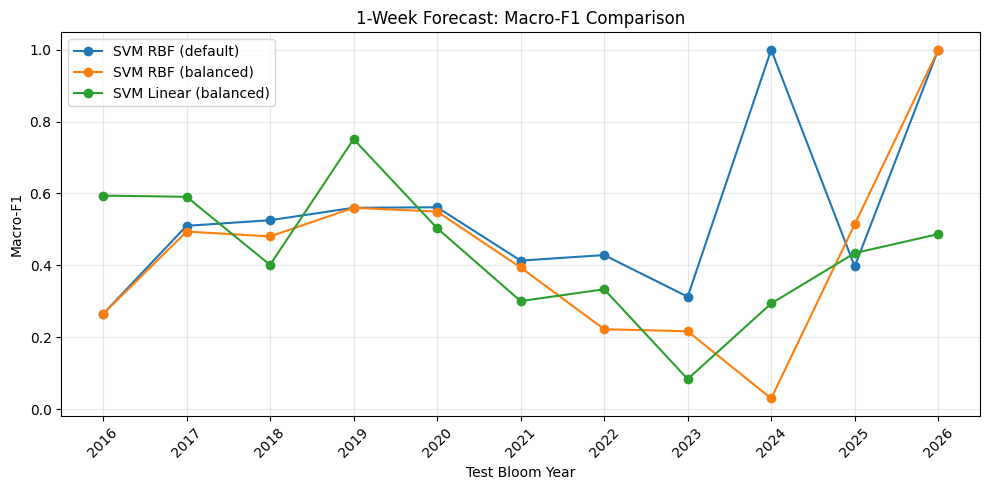

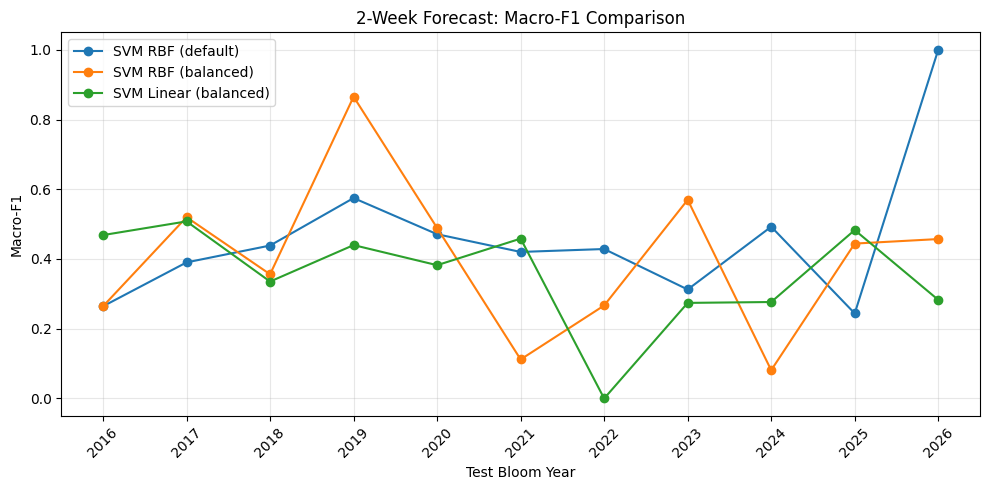

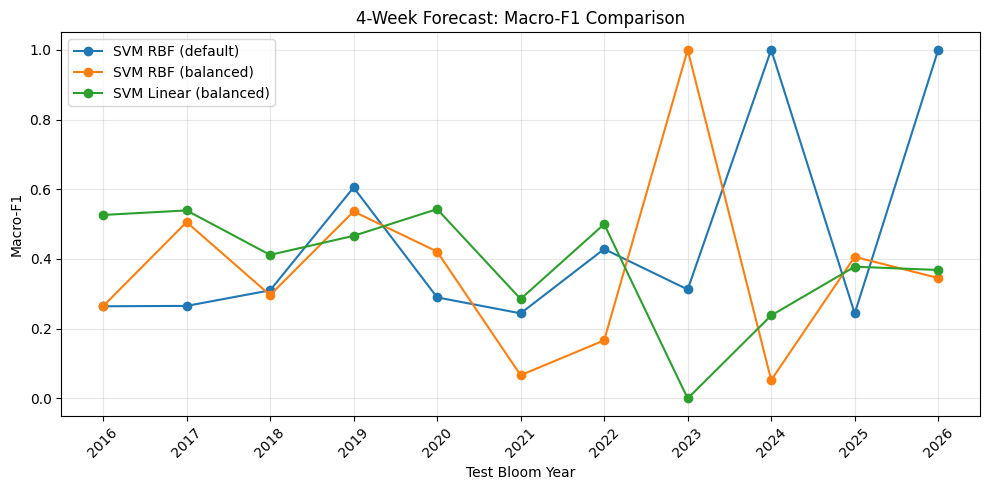

In [8]:
# Plot test-year macro-F1 for each prediction horizon
for horizon in [1, 2, 4]:

    horizon_results = results_df[results_df["horizon"] == horizon]

    plt.figure(figsize=(10, 5))

    for model_name in horizon_results["model"].unique():

        model_results = horizon_results[
            horizon_results["model"] == model_name
        ].sort_values("test_year")

        plt.plot(
            model_results["test_year"],
            model_results["macro_f1"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Test Bloom Year")
    plt.ylabel("Macro-F1")
    plt.title(f"{horizon}-Week Forecast: Macro-F1 Comparison")
    plt.xticks(range(2016, 2027), rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## ROC-AUC by Test Year

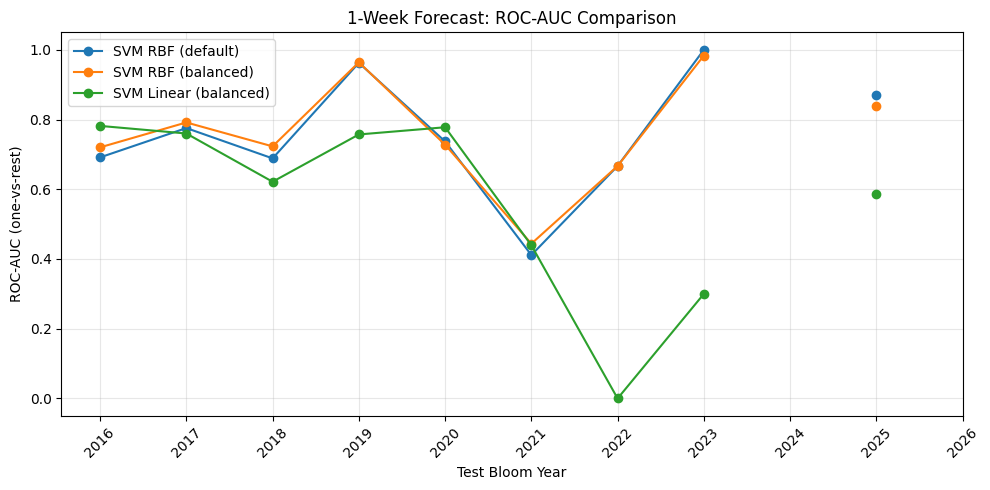

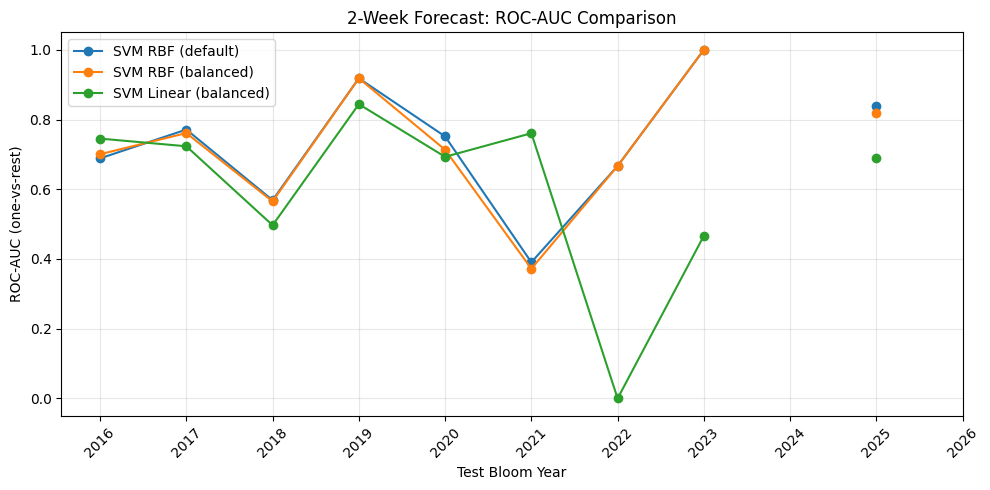

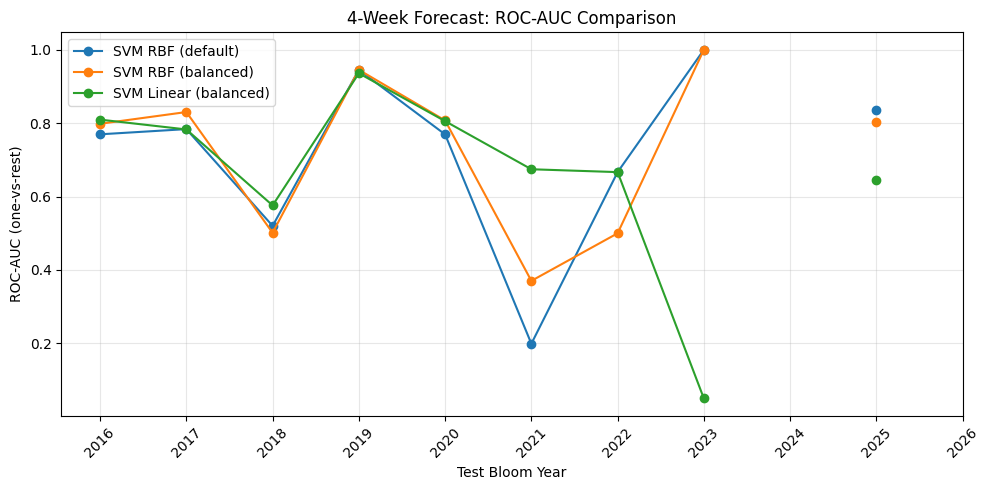

In [9]:
# Plot test-year ROC-AUC for each prediction horizon
for horizon in [1, 2, 4]:

    horizon_results = results_df[results_df["horizon"] == horizon]

    plt.figure(figsize=(10, 5))

    for model_name in horizon_results["model"].unique():

        model_results = horizon_results[
            horizon_results["model"] == model_name
        ].sort_values("test_year")

        plt.plot(
            model_results["test_year"],
            model_results["roc_auc_ovr"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Test Bloom Year")
    plt.ylabel("ROC-AUC (one-vs-rest)")
    plt.title(f"{horizon}-Week Forecast: ROC-AUC Comparison")
    plt.xticks(range(2016, 2027), rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Save the Trained Models

This section trains one final model for each forecast horizon and configuration on all available labeled data and saves it so it can be reused without retraining.

In [10]:
# Folder for saved models
MODEL_DIR = os.path.join(os.getcwd(), "models")
os.makedirs(MODEL_DIR, exist_ok=True)

saved_files = []

for horizon in [1, 2, 4]:

    target = f"target_{horizon}w"

    # Use every week with a known target
    data = dataset.dropna(subset=[target]).copy()

    feature_cols = [col for col in dataset.columns if col not in exclude]
    X = data[feature_cols]
    y = data[target].astype(int)

    # Drop features with no observed values in the full training data
    empty_cols = X.columns[X.isna().all()]
    X = X.drop(columns=empty_cols)

    for model_name, make_model in models.items():

        model = make_model()
        model.fit(X, y)

        # Save the fitted pipeline with the information needed to reuse it
        file_name = (
            f"svm_{model_name.replace('SVM ', '').replace(' ', '_').replace('(', '').replace(')', '').lower()}"
            f"_{horizon}w.joblib"
        )
        file_path = os.path.join(MODEL_DIR, file_name)

        joblib.dump({
            "model": model,
            "features": list(X.columns),
            "horizon_weeks": horizon,
            "configuration": model_name,
            "classes": [int(c) for c in model.classes_],
        }, file_path)

        saved_files.append(file_path)
        print(f"Saved {model_name} ({horizon}-week) -> {file_path}")

print(f"\nSaved {len(saved_files)} models to {MODEL_DIR}")

Saved SVM RBF (default) (1-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_rbf_default_1w.joblib
Saved SVM RBF (balanced) (1-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_rbf_balanced_1w.joblib
Saved SVM Linear (balanced) (1-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_linear_balanced_1w.joblib
Saved SVM RBF (default) (2-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_rbf_default_2w.joblib
Saved SVM RBF (balanced) (2-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_rbf_balanced_2w.joblib
Saved SVM Linear (balanced) (2-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_linear_balanced_2w.joblib
Saved SVM RBF (default) (4-week) -> /content/drive/MyDrive/BTT Fall AI Studio 2026/Google Colab/data/models/svm_rbf_default_4w.joblib
Saved SVM RBF (balanced) (4-week) -> /cont

## Load a Saved Model

In [11]:
# Load a saved model and make predictions
saved = joblib.load(os.path.join(MODEL_DIR, "svm_rbf_default_1w.joblib"))

loaded_model = saved["model"]
loaded_features = saved["features"]

recent_weeks = dataset.tail(5)

example_predictions = loaded_model.predict(recent_weeks[loaded_features])
example_probabilities = loaded_model.predict_proba(recent_weeks[loaded_features])

print(f"{saved['configuration']}, {saved['horizon_weeks']}-week forecast")
print(pd.DataFrame(
    example_probabilities,
    columns=[f"P(class {c})" for c in saved["classes"]],
    index=recent_weeks["week_ending"].dt.date
).assign(predicted_class=example_predictions).round(3))

SVM RBF (default), 1-week forecast
             P(class 0)  P(class 1)  P(class 2)  predicted_class
week_ending                                                     
2026-04-05        0.945       0.043       0.012                0
2026-04-12        0.916       0.050       0.034                0
2026-04-19        0.949       0.045       0.007                0
2026-04-26        0.934       0.056       0.009                0
2026-05-03        0.958       0.036       0.006                0


## Model Performance Summary

| Forecast horizon | Model | Accuracy | Macro-F1 | Macro-precision | Macro-recall | ROC-AUC (OvR) |
| --- | --- | --- | --- | --- | --- | --- |
| 1 week | SVM RBF (default) | 70.94% | 0.5430 | 0.5898 | 0.5941 | 0.7560 |
| 1 week | SVM RBF (balanced) | 56.94% | 0.4295 | 0.5362 | 0.4479 | 0.7620 |
| 1 week | SVM Linear (balanced) | 60.60% | 0.4339 | 0.4574 | 0.4384 | 0.5580 |
| 2 weeks | SVM RBF (default) | 68.50% | 0.4579 | 0.4949 | 0.5162 | 0.7326 |
| 2 weeks | SVM RBF (balanced) | 57.90% | 0.4023 | 0.4750 | 0.4196 | 0.7240 |
| 2 weeks | SVM Linear (balanced) | 50.99% | 0.3553 | 0.4061 | 0.3725 | 0.6020 |
| 4 weeks | SVM RBF (default) | 65.07% | 0.4513 | 0.4777 | 0.5176 | 0.7212 |
| 4 weeks | SVM RBF (balanced) | 50.09% | 0.3692 | 0.4711 | 0.3732 | 0.7285 |
| 4 weeks | SVM Linear (balanced) | 48.87% | 0.3869 | 0.4562 | 0.4039 | 0.6607 |

## Conclusion

The SVM experiment evaluated three configurations at one-, two-, and four-week forecast horizons using forward-chaining evaluation by bloom year. The default RBF SVM was the strongest configuration at every horizon on accuracy, macro-F1, macro-precision, and macro-recall. Its best performance was at one week, and it declined to 65.07% accuracy and 0.4513 macro-F1 at four weeks. Balanced class weights lowered accuracy and macro-F1 at every horizon, and the linear kernel was the weakest option overall.

The RBF SVMs showed moderate class-ranking ability, with one-vs-rest ROC-AUC between 0.72 and 0.76 across horizons. The balanced RBF model had a slightly higher ROC-AUC than the default at one and four weeks. The linear SVM's ROC-AUC was close to chance at one week. Performance also varied widely by year. For example, the default model's one-week accuracy ranged from 45.3% in 2016 to 100% in 2024 and 2026.

## Resources

1. https://scikit-learn.org/stable/modules/svm.html
2. https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html